# Speed of the cohesive coupons: the defaults against 0.17.0 and the options for speed

The coupons of [`delamination.create_coupon`](../cohesive_zone_mixed_mode.rst) assemble and factorize the tangent
stiffness matrix at every Newton-Raphson iteration. After panels 0.17.0 two changes, on by default, make the assembly
faster and change the results at round-off level only:

- the kernels keep the tables of the approximation functions at the integration points on the shell from one call to
  the next, see [Approximation functions tabulated at the integration points](../tabulation.rst);
- Bardell's functions are evaluated by Horner's rule instead of with `pow()`, see
  [Bardell's hierarchical functions](../bardell.rst).

Three options, all off by default, reduce the time further without changing the results beyond the round-off
(see [Options for speed](../cohesive_zone_mixed_mode.rst) and [Plate kernels as matrix products](../plate_blas.rst)):

- `plate_kernels='blas'` of [`MultiDomain`](../multidomain.rst) and `create_coupon`: the plate matrices and vectors
  of `plate_clpt_donnell` and `plate_fsdt_donnell` as products of dense matrices with operators tabulated once per
  domain, [`panels.multidomain.plate_blas`](../plate_blas.rst);
- `reuse_kT=True` of `solve_coupon` and `MultiDomain.get_reduced_functions`: the load vector of the prescribed
  displacement from the tangent already assembled at the same configuration;
- `linear_solver='pardiso_lu'` (oneMKL) or `'dense_lu'` of `structsolve>=0.13.0`, forwarded by `solve_coupon` to
  `structsolve.Analysis`, see the [linear solvers of structsolve](https://saullocastro.github.io/structsolve/linear_solvers.html).

This notebook

1. compares the defaults with panels 0.17.0, for one domain of the size of the cohesive domains of a long coupon:
   matrices, vectors and time of the first and of the later calls;
2. compares, for one domain, the matrices and vectors of the Cython kernels and of `plate_kernels='blas'`, and the
   time of both;
3. runs a DCB coupon with 0.17.0, with the defaults and with the options on, and compares the increments, the
   Newton-Raphson iterations, the load-displacement curves and the run times.

panels 0.17.0 runs in a separate Python process, from the checkout given by the environment variable
`PANELS_0170_PATH` (a checkout of the commit 25d1ecb, built on the same machine, for the stored outputs); the
current version runs in the same way from its own checkout. Without `PANELS_0170_PATH` the comparisons with 0.17.0
are skipped. The helpers are in `coupon_speed_utils.py`, next to this notebook. The times are those of the machine
that ran the notebook, printed below; they depend on its CPU and BLAS library, the equality of the results does
not.

In [1]:
%matplotlib inline
import json
import os
import platform
import subprocess
import sys
import tempfile
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import structsolve
import panels
from coupon_speed_utils import one_domain, tangent_and_fint, dcb


def table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |', '|' + '---|'*len(headers)]
    lines += ['| ' + ' | '.join(str(v) for v in row) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))


def rel(A, B):
    A = A.toarray() if hasattr(A, 'toarray') else np.asarray(A)
    B = B.toarray() if hasattr(B, 'toarray') else np.asarray(B)
    return np.abs(A - B).max()/np.abs(B).max()


def median_time(func, repeat=5):
    func()  # warm-up, also builds the operators of 'blas'
    times = []
    for _ in range(repeat):
        t0 = time.perf_counter()
        func()
        times.append(time.perf_counter() - t0)
    return float(np.median(times))


def linear_solver():
    '''pardiso_lu with oneMKL, else dense_lu, when structsolve has them'''
    try:
        from structsolve.static import LINEAR_SOLVERS
    except ImportError:
        return None
    if 'pardiso_lu' in LINEAR_SOLVERS:
        try:
            from structsolve.pardiso import load_mkl
            load_mkl()
            return 'pardiso_lu'
        except Exception:
            pass
    return 'dense_lu' if 'dense_lu' in LINEAR_SOLVERS else None


def commit(path):
    try:
        return subprocess.run(['git', '-C', path, 'rev-parse', '--short', 'HEAD'], capture_output=True,
                              text=True, check=True).stdout.strip()
    except Exception:
        return 'unknown'


PANELS_NOW = os.path.dirname(os.path.dirname(os.path.abspath(panels.__file__)))
PANELS_0170 = os.environ.get('PANELS_0170_PATH')


def run_with(path, *args):
    '''coupon_speed_utils.py in a new Python process with the panels of ``path``; the JSON it prints'''
    env = dict(os.environ, PYTHONPATH=path)
    out = subprocess.run([sys.executable, 'coupon_speed_utils.py', *args], env=env, capture_output=True,
                         text=True, check=True)
    return json.loads(out.stdout.strip().splitlines()[-1])


from structsolve.static import LINEAR_SOLVERS
print('panels: this version, on commit', commit(PANELS_NOW), '| structsolve linear solvers',
      LINEAR_SOLVERS, '| numpy', np.__version__)
print('panels 0.17.0:', 'commit %s' % commit(PANELS_0170) if PANELS_0170 else 'not given, comparisons skipped')
print(platform.processor(), '|', os.cpu_count(), 'logical CPUs')
SOLVER = linear_solver()
print('linear solver of the options:', SOLVER)

panels: this version, on commit 55a887a | structsolve linear solvers ('splu', 'pardiso', 'pardiso_lu', 'dense_lu') | numpy 2.4.4
panels 0.17.0: commit 25d1ecb
AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD | 16 logical CPUs
linear solver of the options: pardiso_lu


## 1. The defaults against panels 0.17.0

One domain of $20 \times 25.4$ mm, $[0]_{12}$ AS4/PEEK, with $m = 24$, $n = 4$ terms and $240 \times 6$
Gauss-Legendre points, as the long cohesive domains of a coupon, at a random configuration: the tangent ($K_C$ and
$K_G$ with `NLgeom=True`) and the internal force vector, assembled with `MultiDomain([p], conn=[])` and the default
Cython kernels, by this version and by 0.17.0, each in its own process. The time of the first call on a new domain
includes filling the tables; the later calls on the same domain only read them, whereas 0.17.0 filled them at every
call.

In [2]:
rows = []
if PANELS_0170:
    tmp = tempfile.mkdtemp()
    for model in ('plate_clpt_donnell', 'plate_fsdt_donnell'):
        res = {}
        for name, path in (('now', PANELS_NOW), ('0.17.0', PANELS_0170)):
            out = os.path.join(tmp, '%s_%s.npz' % (model, name.replace('.', '')))
            times = run_with(path, 'domain', model, out, '9')
            with np.load(out) as data:
                res[name] = (times, [data['arr_%d' % i] for i in range(3)])
        (t_now, a_now), (t_old, a_old) = res['now'], res['0.17.0']
        rows.append(['`%s`' % model] + ['%.1e' % rel(a, b) for a, b in zip(a_now, a_old)]
                    + ['%.3f' % t_old['first'], '%.3f' % t_now['first'], '%.2f' % (t_old['first']/t_now['first']),
                       '%.3f' % t_old['later'], '%.3f' % t_now['later'], '%.2f' % (t_old['later']/t_now['later'])])
    table(['model', '$K_C$', '$K_G$', '$F_{int}$', 'first, 0.17.0 (s)', 'first (s)', 'speed-up',
           'later, 0.17.0 (s)', 'later (s)', 'speed-up'], rows)
else:
    print('PANELS_0170_PATH not set: comparison with 0.17.0 skipped')

| model | $K_C$ | $K_G$ | $F_{int}$ | first, 0.17.0 (s) | first (s) | speed-up | later, 0.17.0 (s) | later (s) | speed-up |
|---|---|---|---|---|---|---|---|---|---|
| `plate_clpt_donnell` | 2.0e-10 | 4.2e-10 | 1.3e-10 | 0.288 | 0.251 | 1.15 | 0.198 | 0.167 | 1.19 |
| `plate_fsdt_donnell` | 4.7e-12 | 9.2e-10 | 5.9e-12 | 0.350 | 0.238 | 1.47 | 0.230 | 0.167 | 1.38 |

The columns $K_C$ to $F_{int}$ are the largest difference from 0.17.0 over the largest entry. They are not at the
level of the unit round-off, $10^{-16}$, because the terms of high degree of Bardell's functions lose digits by
cancellation in any evaluation of their monomial form, and Horner's rule with correctly rounded coefficients is the
more accurate of the two, see [Bardell's hierarchical functions](../bardell.rst). The times are medians of 9 calls of
$K_C + K_G + F_{int}$; the later calls are those of the Newton-Raphson iterations of an analysis.

## 2. One domain: Cython kernels against `plate_kernels='blas'`

A domain of $20 \times 25.4$ mm, $[0]_{12}$ AS4/PEEK, $m = 15$, $n = 6$ terms and $60 \times 10$ Gauss-Legendre
points, as the cohesive domains of the coupons, at a random configuration: the tangent ($K_C$ and $K_G$ with
`NLgeom=True`), the internal force vector and the product of the tangent by a vector, assembled with
`MultiDomain([p], conn=[])` and either option.

In [3]:
rows = []
for model in ('plate_clpt_donnell', 'plate_fsdt_donnell'):
    mds = {k: one_domain(model, plate_kernels=k) for k in ('cython', 'blas')}
    rng = np.random.default_rng(0)
    c = 1e-2*rng.standard_normal(mds['cython'].get_size())
    v = rng.standard_normal(c.size)
    res, times = {}, {}
    for k, md_ in mds.items():
        kC, kG, fint = tangent_and_fint(md_, c)
        res[k] = dict(kC=kC, kG=kG, fint=fint, kTv=md_.calc_kTv(c, v))
        times[k] = median_time(lambda: tangent_and_fint(md_, c))
    rows.append(['`%s`' % model] + ['%.1e' % rel(res['blas'][k], res['cython'][k]) for k in res['blas']]
                + ['%.3f' % times['cython'], '%.3f' % times['blas'], '%.1f' % (times['cython']/times['blas'])])
table(['model', '$K_C$', '$K_G$', '$F_{int}$', '$K_T v$', 'Cython (s)', 'blas (s)', 'speed-up'], rows)

| model | $K_C$ | $K_G$ | $F_{int}$ | $K_T v$ | Cython (s) | blas (s) | speed-up |
|---|---|---|---|---|---|---|---|
| `plate_clpt_donnell` | 2.7e-15 | 3.4e-15 | 2.9e-15 | 3.7e-15 | 0.087 | 0.021 | 4.2 |
| `plate_fsdt_donnell` | 5.1e-15 | 3.7e-15 | 3.0e-15 | 3.6e-15 | 0.097 | 0.037 | 2.6 |

The columns $K_C$ to $K_T v$ are the largest difference over the largest entry: the round-off. The times are those
of one tangent and one internal force vector, $K_C + K_G + F_{int}$, the median of 5 evaluations after a warm-up,
i.e. with the tables of the Cython kernels already filled.

## 3. A DCB coupon: 0.17.0, the defaults and the options

The DCB of AS4/PEEK, $25.4$ mm wide, arms of $[0]_{12}$, $0.13$ mm plies, $a_0 = 30$ mm, $60$ mm long, with the
bilinear law of the tests of the coupons (used for verification only), CLPT, three cohesive domains of 15 terms over
the first $15$ mm of the bonded length, up to an opening $\delta = 3$ mm, past the onset of the damage, in increments
of $0.25$ mm. The Newton-Raphson iterations of each increment are counted as the evaluations of the tangent. The run
with 0.17.0 uses its defaults, in its own process.

In [4]:
runs = {}
if PANELS_0170:
    r = run_with(PANELS_0170, 'dcb')
    runs['panels 0.17.0'] = {k: np.asarray(v) for k, v in r.items()}
runs['defaults'] = dcb(False)
runs["plate_kernels='blas', reuse_kT=True"] = dcb(True)
if SOLVER is not None:
    runs["plate_kernels='blas', reuse_kT=True, linear_solver='%s'" % SOLVER] = dcb(True, linear_solver=SOLVER)
ref = runs['defaults']
old = runs.get('panels 0.17.0')
rows = []
for name, r in runs.items():
    same = len(r['delta']) == len(ref['delta'])
    rows.append([name, len(r['delta']), same and np.array_equal(r['delta'], ref['delta']),
                 same and np.array_equal(r['iterations'], ref['iterations']), int(r['iterations'].sum()),
                 '%.1e' % np.abs(r['P'] - ref['P']).max() if same else '-', '%.1f' % r['time'],
                 '%.2f' % (ref['time']/r['time']),
                 '%.2f' % (old['time']/r['time']) if old is not None else '-'])
table(['run', 'increments', 'same $\\delta$', 'same iterations', 'iterations',
       'max $\\lvert \\Delta P \\rvert$ (N)', 'time (s)', 'speed-up vs defaults', 'speed-up vs 0.17.0'], rows)
print('largest damage variable at the end: %.3f' % ref['max_d'][-1])

| run | increments | same $\delta$ | same iterations | iterations | max $\lvert \Delta P \rvert$ (N) | time (s) | speed-up vs defaults | speed-up vs 0.17.0 |
|---|---|---|---|---|---|---|---|---|
| panels 0.17.0 | 12 | True | True | 26 | 1.9e-11 | 20.7 | 0.97 | 1.00 |
| defaults | 12 | True | True | 26 | 0.0e+00 | 20.1 | 1.00 | 1.03 |
| plate_kernels='blas', reuse_kT=True | 12 | True | True | 26 | 3.2e-11 | 13.3 | 1.51 | 1.56 |
| plate_kernels='blas', reuse_kT=True, linear_solver='pardiso_lu' | 12 | True | True | 26 | 6.1e-11 | 9.8 | 2.05 | 2.12 |

largest damage variable at the end: 0.976


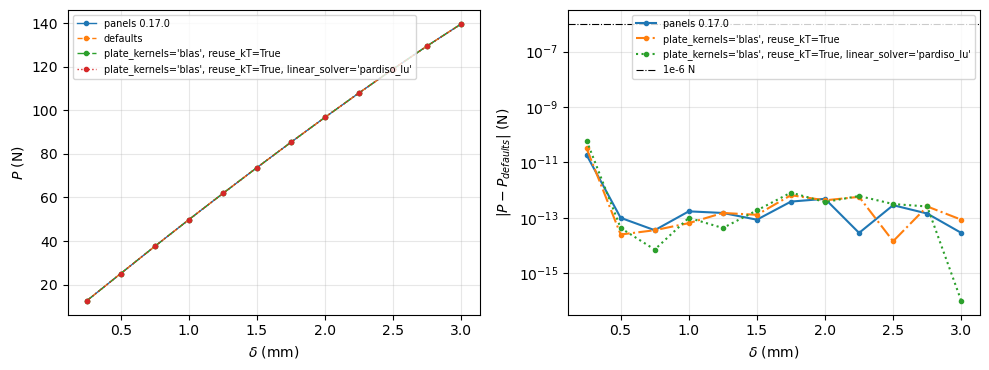

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for (name, r), ls in zip(runs.items(), ('-', '--', '-.', ':')):
    axes[0].plot(r['delta'], r['P'], ls, marker='o', ms=3, lw=1, label=name)
    if r is not ref:
        axes[1].semilogy(r['delta'], np.maximum(np.abs(r['P'] - ref['P']), 1e-16), ls, marker='o', ms=3,
                         label=name)
axes[0].set_xlabel(r'$\delta$ (mm)')
axes[0].set_ylabel('$P$ (N)')
axes[0].legend(fontsize=7)
axes[1].axhline(1e-6, color='k', lw=0.8, ls='-.', label='1e-6 N')
axes[1].set_xlabel(r'$\delta$ (mm)')
axes[1].set_ylabel(r'$|P - P_{defaults}|$ (N)')
axes[1].legend(fontsize=7)
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The defaults give the same increments and iterations as 0.17.0, with loads that differ by the round-off of the new
evaluation of Bardell's functions; the options give the same increments and the same iterations as the defaults, and
loads that differ by the round-off, far below $10^{-6}$ N; the curves overlap. For this DCB the defaults take only a few percent less
time than 0.17.0: with 15 by 6 terms per cohesive domain the tables are a small part of the
assembly, whose loops over the pairs of terms are unchanged; the gain of the defaults is larger for long domains
with many points and few terms, as in section 1. The speed-up of the options grows with
the number of terms and of points of the cohesive domains, whose plate kernels dominate the time with the defaults,
and the faster factorizations matter once the plate kernels are fast. `tests/multidomain/test_plate_blas.py` checks
the same equalities of the options on a smaller DCB, and `tests/tests_shell/test_kernel_references.py` the kernels of
all the models against stored outputs of 0.17.0.